In [24]:
#Code with the topic: Hierarchical Clustering

#Objective: 

#Group students into clusters based on their characteristics
#using Hierarchical Clustering and visualize the results with a dendrogram.

#Technologies:

#Pandas
#Matplotlib
#Scikit learn
#SciPy
#Visual Studio Code
#Jupyter Notebook

#Mehtod used:

#HAgglamerative
#Clustring
#Assigments

In [25]:
#Import the libraries

import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

In [26]:
#Load the dataset

data = pd.read_csv("Hierarchical_Clustering.csv")

In [27]:
#Visualization

data.head()

,Age,StudyHours,Attendance,Grade,Class
0,18,5,90,85,A
1,19,6,95,92,A
2,20,2,70,65,B
3,21,3,75,68,B
4,22,8,98,96,A


In [28]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Age         6 non-null      int64 
 1   StudyHours  6 non-null      int64 
 2   Attendance  6 non-null      int64 
 3   Grade       6 non-null      int64 
 4   Class       6 non-null      object
dtypes: int64(4), object(1)
memory usage: 372.0+ bytes


In [29]:
data.describe()

,Age,StudyHours,Attendance,Grade
count,6.000000,6.000000,6.000000,6.000000
mean,20.000000,4.166667,81.333333,76.833333
std,1.414214,2.639444,15.253415,16.485347
min,18.000000,1.000000,60.000000,55.000000
25%,19.250000,2.250000,71.250000,65.750000
50%,20.000000,4.000000,82.500000,76.500000
75%,20.750000,5.750000,93.750000,90.250000
max,22.000000,8.000000,98.000000,96.000000


In [30]:
#Separate features and labels

X = data.drop("Class", axis=1)
y = data["Class"]

In [31]:
#Standardize the data

scaler = StandardScaler()
x_scaled = scaler.fit_transform(X)


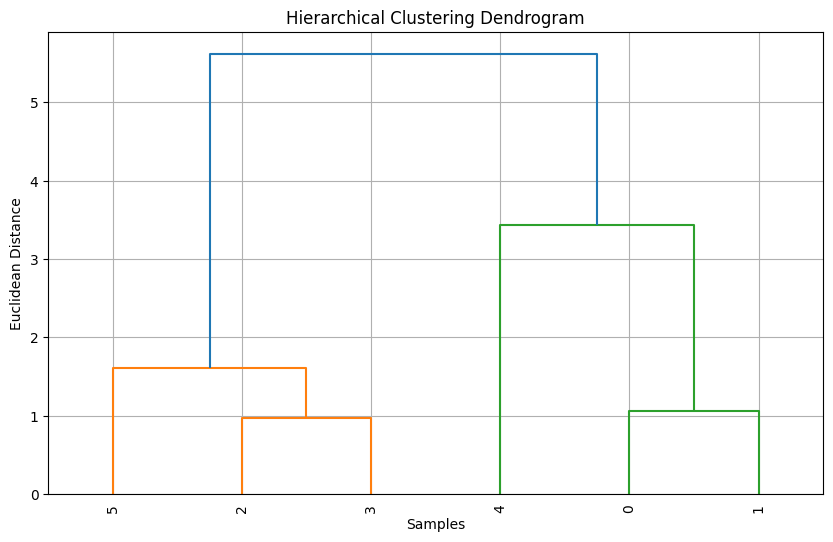

In [32]:
#Create the linkage matrix for the dendrogram

linkage_matrix = linkage(
    x_scaled,
    method="ward"
)

#Plot the dendrogram

plt.figure(figsize=(10,6))

dendrogram(
    linkage_matrix,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Samples")
plt.ylabel("Euclidean Distance")

plt.grid(True)
plt.show()

In [33]:
#Configure the Hierarchical Clustering model
#Based on the dendrogram, we choose 3 clusters.

model = AgglomerativeClustering(
    n_clusters=3,
    metric="euclidean",
    linkage="ward"

)

In [34]:
#Train the model 

clusters = model.fit_predict(x_scaled)

In [35]:
#Store the clustring results

result = pd.DataFrame({
    "Clusters": clusters,
    "Actual_Class": y
})

print("\n Cluster Assigments:")
print(result.head())




 Cluster Assigments:
   Clusters Actual_Class
0         1            A
1         1            A
2         0            B
3         0            B
4         2            A


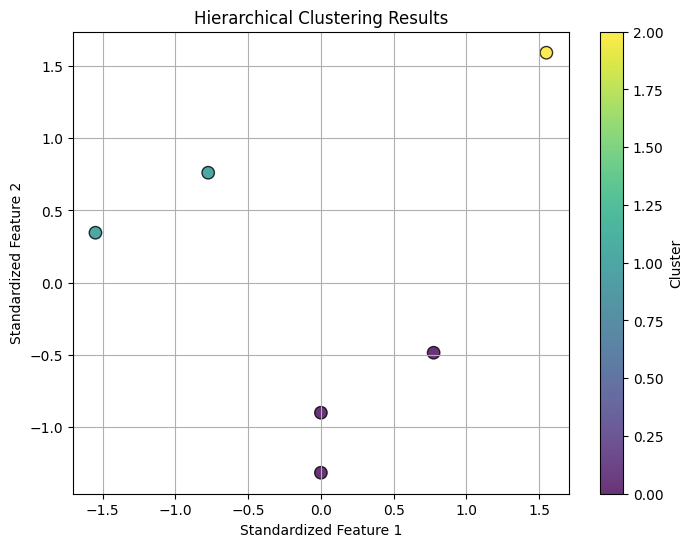

In [36]:
#Visualize the clusters using thr firts two standardized features

plt.figure(figsize=(8,6))

scatter = plt.scatter(
    x_scaled[:,0],
    x_scaled[:,1],
    c=clusters,
    cmap="viridis",
    s=80,
    edgecolors="black",
    alpha=0.8
)

plt.title("Hierarchical Clustering Results")
plt.xlabel("Standardized Feature 1")
plt.ylabel("Standardized Feature 2")

plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()